# USPTO + Local AI Patent Analysis

This capstone combines USPTO retrieval with four local AI tasks: OCR patent pages with DeepSeek-OCR, summarize the text with Gemma 3, describe a drawing with Qwen3-VL, and estimate relevance to a prior-art search topic with Strands Decider.

The AI outputs are tools for exploration and screening, not legal determinations.


## 1. Setup

This notebook assumes Ollama is installed and running, the models have already been downloaded, and your USPTO API key is stored in `config.yml` as `api_key: YOUR_USPTO_API_KEY`.

Generated PDFs and images are written to a local `data/` directory rather than the repository root.


In [2]:
import requests
import yaml
import pandas as pd
import fitz
import ollama

from pathlib import Path

from IPython.display import Image, display

with open("config.yml", "r") as f:
    config = yaml.safe_load(f)

API_KEY = config["uspto_api_key"]
BASE_URL = "https://api.uspto.gov/api/v1/patent/applications"

headers = {
    "X-API-KEY": API_KEY,
    "Accept": "application/json"
}

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)


## 2. Choose a Patent and Prior-Art Topic

Change these values to investigate another application and research question. Enter the application number without punctuation.


In [26]:
APPLICATION_NUMBER = "15694515"

PRIOR_ART_TOPIC = (
    #"Nonlinear optimization based methods to reduce traffic disruptions in autonomous vehicles",
    "Improved manual pressure valve release for inhaled asthma treatments"
)


## 3. Retrieve the Patent Application


In [4]:
url = f"{BASE_URL}/{APPLICATION_NUMBER}"

response = requests.get(url, headers=headers)
response.raise_for_status()

application = response.json()
record = application["patentFileWrapperDataBag"][0]
metadata = record["applicationMetaData"]

print("Title:", metadata.get("inventionTitle"))
print("Application:", metadata.get("applicationNumberText"))
print("Publication:", metadata.get("earliestPublicationNumber"))
print("First inventor:", metadata.get("firstInventorName"))
print("Status:", metadata.get("applicationStatusDescriptionText"))


Title: System and Method for Solving Large Scale Supply Chain Planning Problems with Integer Constraints
Application: None
Publication: US20170364847A1
First inventor: Narasimha B. Kamath
Status: Patented Case


## 4. Retrieve the File Wrapper

Inspect the application document list so we can find a specification and drawings.


In [5]:
url = f"{BASE_URL}/{APPLICATION_NUMBER}/documents"

response = requests.get(url, headers=headers)
response.raise_for_status()

documents = response.json()
doc_list = []

for doc in documents.get("documentBag", []):
    pdf_options = [
        option
        for option in doc.get("downloadOptionBag", [])
        if option.get("mimeTypeIdentifier") == "PDF"
    ]

    doc_list.append({
        "date": doc.get("officialDate"),
        "code": doc.get("documentCode"),
        "description": doc.get("documentCodeDescriptionText"),
        "pages": pdf_options[0].get("pageTotalQuantity") if pdf_options else None,
        "pdf_url": pdf_options[0].get("downloadUrl") if pdf_options else None
    })

docs_df = pd.DataFrame(doc_list)
docs_df.head(20)


,date,code,description,pages,pdf_url
0,2023-06-27T00:00:00.000-0400,COCOUT,Certificate of Correction - Post Issue Communi...,3,https://api.uspto.gov/api/v1/download/applicat...
1,2023-05-31T17:21:24.000-0400,COCIN,Request for Certificate of Correction,9,https://api.uspto.gov/api/v1/download/applicat...
2,2023-05-31T17:21:24.000-0400,COCIN,Request for Certificate of Correction,7,https://api.uspto.gov/api/v1/download/applicat...
3,2023-05-31T17:21:24.000-0400,N417,Electronic Filing System Acknowledgment Receipt,2,https://api.uspto.gov/api/v1/download/applicat...
4,2019-05-29T15:22:15.000-0400,ISSUE.NTF,Issue Notification,1,https://api.uspto.gov/api/v1/download/applicat...
5,2019-04-18T13:20:06.000-0400,LET.,Miscellaneous Incoming Letter,3,https://api.uspto.gov/api/v1/download/applicat...
6,2019-04-18T13:20:06.000-0400,IFEE,Issue Fee Payment (PTO-85B),1,https://api.uspto.gov/api/v1/download/applicat...
7,2019-04-18T13:20:06.000-0400,WFEE,Fee Worksheet (SB06),2,https://api.uspto.gov/api/v1/download/applicat...
8,2019-04-18T13:20:06.000-0400,N417,Electronic Filing System Acknowledgment Receipt,2,https://api.uspto.gov/api/v1/download/applicat...
9,2019-04-16T17:27:22.000-0400,DRW,Drawings-only black and white line drawings,3,https://api.uspto.gov/api/v1/download/applicat...


## 5. Download the Specification

Look for a document whose description contains `specification`. If another application uses different labels, inspect `docs_df`.


In [6]:
text_docs = docs_df[
    docs_df["description"].str.contains(
        "specification",
        case=False,
        na=False
    )
].dropna(subset=["pdf_url"])

text_docs[["date", "code", "description", "pages"]]


,date,code,description,pages
55,2017-09-01T00:00:00.000-0400,SPEC,Specification,26


In [7]:
if text_docs.empty:
    raise ValueError(
        "No specification PDF was found. "
        "Inspect docs_df and choose another text document."
    )

text_row = text_docs.iloc[0]

response = requests.get(
    text_row["pdf_url"],
    headers=headers
)
response.raise_for_status()

specification_pdf = DATA_DIR / f"{APPLICATION_NUMBER}_specification.pdf"

with open(specification_pdf, "wb") as f:
    f.write(response.content)

print("Saved:", specification_pdf)


Saved: data/15694515_specification.pdf


## 6. Render Patent Pages for OCR

DeepSeek-OCR works with images, so render a few pages from the specification PDF. `OCR_PAGES` keeps the example manageable.


In [8]:
OCR_PAGES = 5

pdf = fitz.open(specification_pdf)
page_images = []

for page_number in range(min(OCR_PAGES, len(pdf))):
    page = pdf[page_number]
    pix = page.get_pixmap(matrix=fitz.Matrix(2, 2))

    filename = DATA_DIR / (
        f"{APPLICATION_NUMBER}_"
        f"spec_page_{page_number + 1}.png"
    )

    pix.save(filename)
    page_images.append(filename)

pdf.close()

page_images


[PosixPath('data/15694515_spec_page_1.png'),
 PosixPath('data/15694515_spec_page_2.png'),
 PosixPath('data/15694515_spec_page_3.png'),
 PosixPath('data/15694515_spec_page_4.png'),
 PosixPath('data/15694515_spec_page_5.png')]

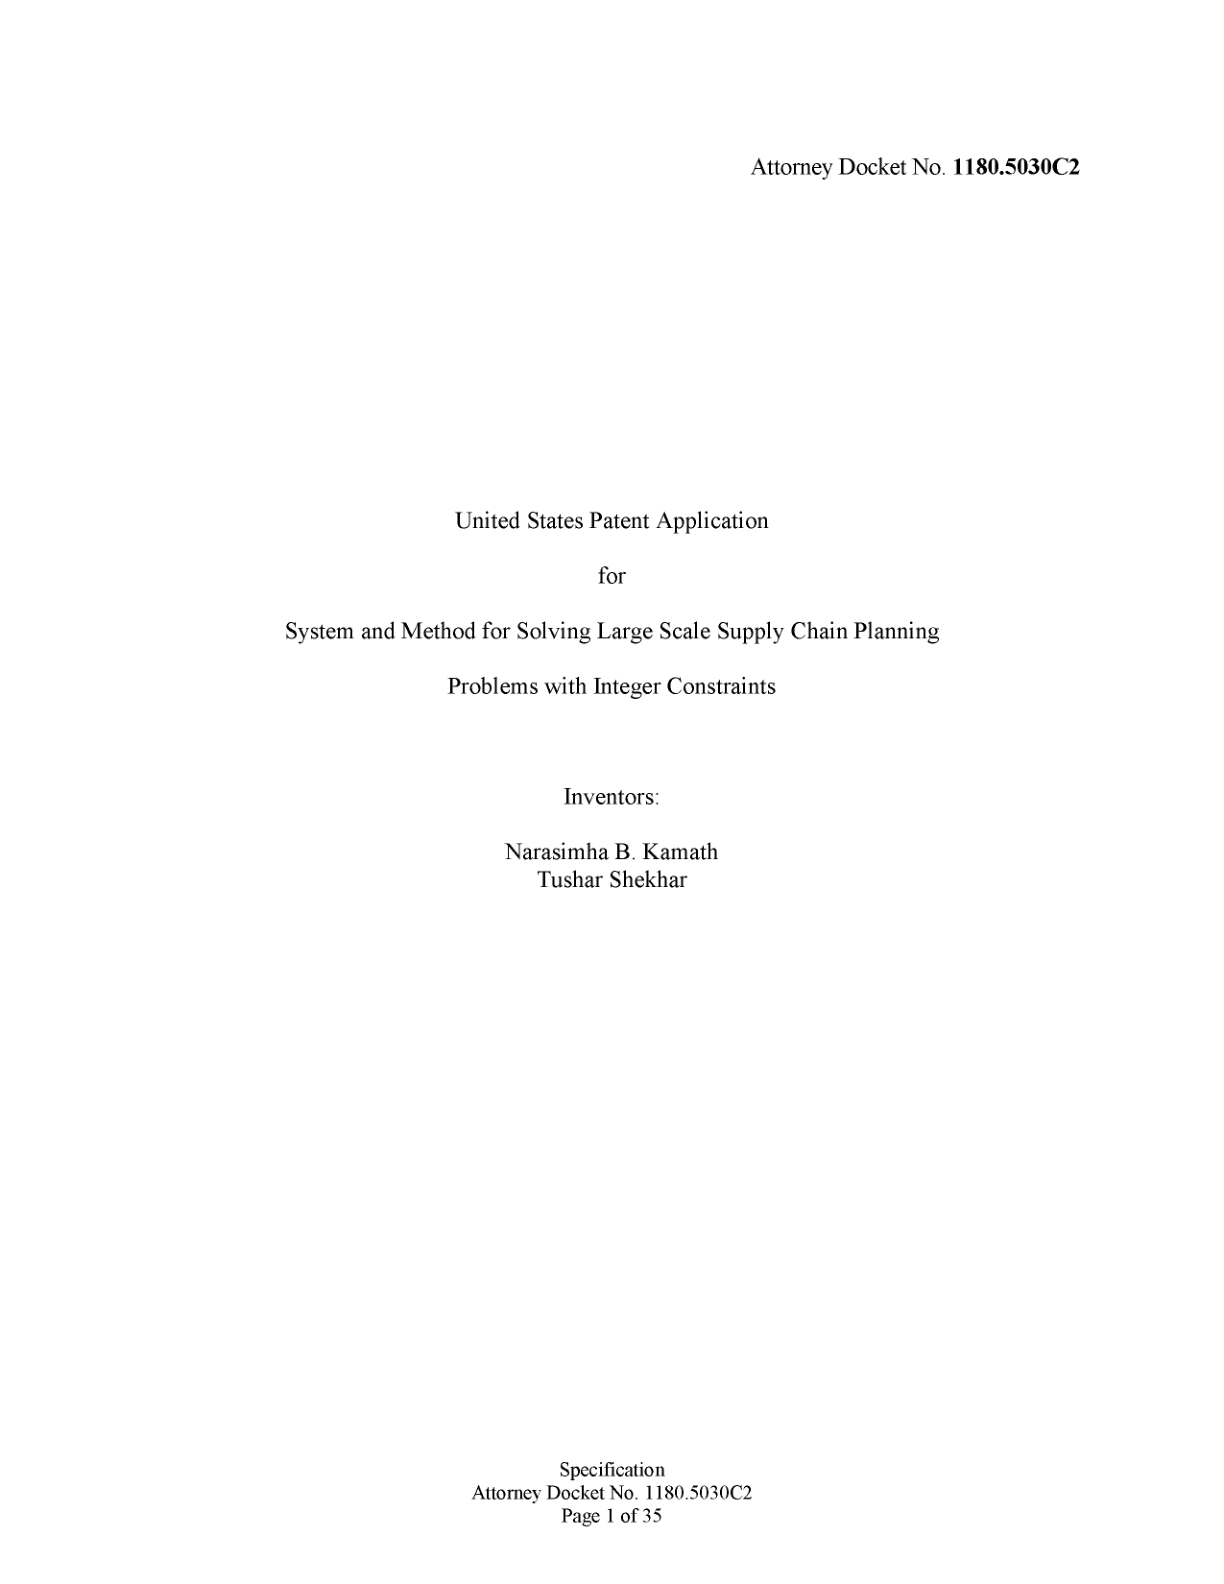

In [9]:
display(
    Image(
        filename=str(page_images[0]),
        width=800
    )
)


## 7. Extract Patent Text with DeepSeek-OCR

First, test the OCR model on a single page.

This uses the same model and simple prompt as the Local AI with Ollama workshop. Compare the OCR output with the displayed page before processing additional pages.


In [10]:
model = "deepseek-ocr"

prompt = "Extract the text in the image"

response = ollama.generate(
    model=model,
    prompt=prompt,
    images=[str(page_images[0])]
)

print(response["response"])


ISSN 1108.5030C2

United States Patent Application

for

System and Method for Solving Large Scale Supply Chain Planning

Problems with Integer Constraints

Inventors:

Narasimha B.Kamath

Tushar Shekhar

Specification

Attorney Docket No.1180.5030C2

Page 1 of 35


If the first-page OCR looks reasonable, process the small set of rendered pages and combine the text.

This is a teaching example rather than a robust OCR pipeline.


In [11]:
ocr_pages = []

for image_path in page_images:
    print("Reading:", image_path)

    response = ollama.generate(
        model=model,
        prompt=prompt,
        images=[str(image_path)]
    )

    ocr_pages.append(response["response"])

patent_text = "\n\n".join(ocr_pages)

print(patent_text[:5000])


Reading: data/15694515_spec_page_1.png
Reading: data/15694515_spec_page_2.png
Reading: data/15694515_spec_page_3.png
Reading: data/15694515_spec_page_4.png
Reading: data/15694515_spec_page_5.png
ISSN 1108.5030C2

United States Patent Application

for

System and Method for Solving Large Scale Supply Chain Planning

Problems with Integer Constraints

Inventors:

Narasimha B.Kamath

Tushar Shekhar

Specification

Attorney Docket No.1180.5030C2

Page 1 of 35

atts

CROSS-REFERENCE TO RELATED APPLICATIONS

[0001]This application is a continuation of U.S. Patent Application No. 13/867,310 filed on

April 22, 2013 and entitled "System and Method for Solving Large Scale Supply Chain Planning

Problems with Integer Constraints," which is a continuation of U.S. Patent Application No.

12/860,683 filed on August 20, 2010 and entitled "System and Method of Solving Large Scale

Supply Chain Planning Problems with Integer Constraints," now U.S. Patent No. 8,429,035, which

claims the benefit of U.S

## 8. Summarize the Patent with Gemma 3

Now use the OCR text as document context for Gemma 3.

This follows the same pattern as the Document-Chat workbook: supply the document as context, then ask a straightforward question about it.


In [12]:
model = "gemma3"

prompt = f"""
You are a document analysis assistant.

Answer questions using only the document below.
If the document does not contain enough information to answer a question,
say so rather than making up an answer.

DOCUMENT:
{patent_text}
"""

messages = [
    {"role": "system", "content": prompt},
    {
        "role": "user",
        "content": (
            "What is this patent about? Summarize the problem, "
            "the proposed invention, and its main components or methods."
        )
    }
]

response = ollama.chat(
    model=model,
    messages=messages
)

summary = response["message"]["content"]
print(summary)


Here’s a summary of the patent document, based on the provided text:

**Problem:**

The patent addresses the difficulty of solving large-scale supply chain planning problems, particularly those with integer constraints (like lot sizing and capacity restrictions). Existing methods had significant shortcomings:

*   **Decomposition with LP:**  Didn’t handle discrete constraints effectively.
*   **Order-by-Order Solvers:** Sequence-based and lacked global optimization.
*   **Mixed Integer Programs (MIPs):**  NP-hard, leading to extremely long solution times for large datasets.
*   **Heuristic Repair:**  Using rounding or adjustments to LP solutions was inadequate due to a lack of consideration for the overall hierarchical objectives.

**Proposed Invention:**

The invention proposes a system and method for solving these complex supply chain planning problems by:

*   Modeling the supply chain network as a hierarchical network of nodes and edges.
*   Generating a hierarchical linear program

## 9. Download a Patent Drawing

Return to the file-wrapper list and look for drawing documents.


In [13]:
drawings_df = docs_df[
    docs_df["description"].str.contains(
        r"draw|figure|fig\.",
        case=False,
        na=False,
        regex=True
    )
].dropna(subset=["pdf_url"])

drawings_df[["date", "code", "description", "pages"]]


,date,code,description,pages
9,2019-04-16T17:27:22.000-0400,DRW,Drawings-only black and white line drawings,3
60,2017-09-01T00:00:00.000-0400,DRW,Drawings-only black and white line drawings,4


In [14]:
if drawings_df.empty:
    raise ValueError(
        "No drawing PDF was found. "
        "Inspect docs_df and choose another document."
    )

drawing_row = drawings_df.iloc[0]

response = requests.get(
    drawing_row["pdf_url"],
    headers=headers
)
response.raise_for_status()

drawing_pdf = DATA_DIR / f"{APPLICATION_NUMBER}_drawings.pdf"

with open(drawing_pdf, "wb") as f:
    f.write(response.content)

print("Saved:", drawing_pdf)


Saved: data/15694515_drawings.pdf


Render one drawing page as an image. Change `DRAWING_PAGE` to inspect another page.


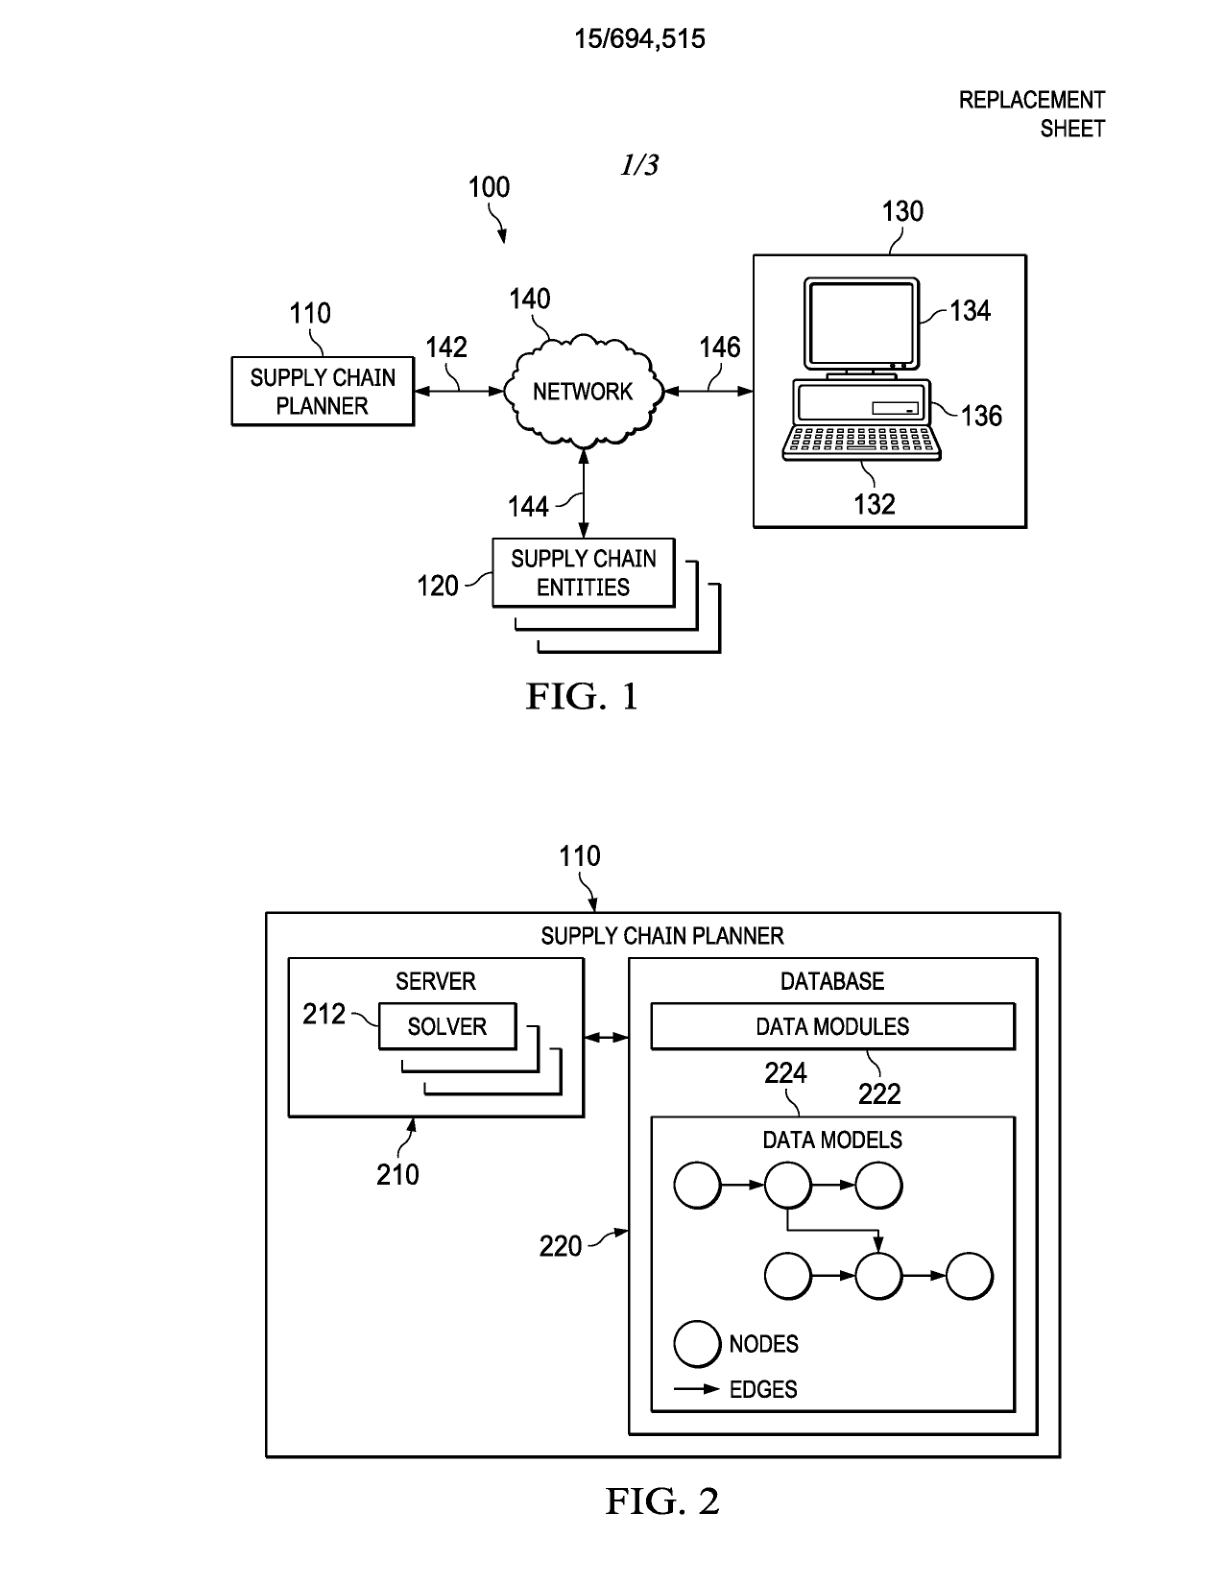

In [15]:
DRAWING_PAGE = 0

pdf = fitz.open(drawing_pdf)
page = pdf[DRAWING_PAGE]
pix = page.get_pixmap(matrix=fitz.Matrix(2, 2))

drawing_image = DATA_DIR / (
    f"{APPLICATION_NUMBER}_"
    f"drawing_page_{DRAWING_PAGE + 1}.png"
)

pix.save(drawing_image)
pdf.close()

display(Image(filename=str(drawing_image), width=800))


## 10. Describe the Drawing with Qwen3-VL


In [16]:
model = "qwen3-vl:2b-instruct"

prompt = "Describe this image in detail."

response = ollama.generate(
    model=model,
    prompt=prompt,
    images=[str(drawing_image)],
    options={
        "num_ctx": 8192,
        "num_predict": 4096,
        "temperature": 0.7
    }
)

drawing_description = response["response"]
print(drawing_description)


This image displays two figures from a patent, likely for a supply chain planning system. The figures illustrate the system's components and architecture.

---

**FIG. 1**

This diagram shows the high-level architecture of a supply chain planning system. It consists of the following components and their relationships:

- **Supply Chain Planner**: A rectangular block labeled "SUPPLY CHAIN PLANNER" (110) is connected to the network via a line labeled 142.
- **Network**: Represented by a cloud shape, the "NETWORK" (140) is the central communication medium.
- **Supply Chain Entities**: This is a block labeled "SUPPLY CHAIN ENTITIES" (120). It is connected to the network via line 144.
- **Computer System**: On the right, a computer system is depicted. It consists of a monitor (134) and a keyboard (136) connected to a processing unit (132) inside a computer case. The computer system is connected to the network via line 146.

The diagram shows the flow of data and communication from the suppl

## 11. Screen for Prior-Art Relevance

Use Strands Decider to estimate whether this patent is relevant to the prior-art search topic. The returned percentages are screening scores, not legal conclusions.


In [27]:
PRIOR_ART_TOPIC

'Improved manual pressure valve release for inhaled asthma treatments'

In [28]:
model = "strands-decider:2b"

text = f"""
PRIOR-ART SEARCH TOPIC:

{PRIOR_ART_TOPIC}

CANDIDATE PATENT:

Title:
{metadata.get("inventionTitle")}

Patent text:
{patent_text}
"""

questions = {
    "prior_art_relevance": {
        "type": "choice",
        "instructions": "Classify this patent for the prior-art search.",
        "criteria": {
            "relevant": (
                "The patent is sufficiently related to the search topic "
                "that it should be reviewed more closely."
            ),
            "not_relevant": (
                "The patent is not sufficiently related to the search topic "
                "to warrant closer review."
            )
        }
    }
}

response = ollama.systemone(
    model=model,
    state=text,
    questions=questions
)


In [29]:
decision = response.answers["prior_art_relevance"]

print("Classification:", decision.choice)
print()

for label, probability in decision.probabilities.items():
    print(f"{label}: {probability * 100:.1f}%")


Classification: not_relevant

relevant: 35.7%
not_relevant: 64.3%


## 12. The Mini Pipeline

We used four local models for four different tasks:

- DeepSeek-OCR: What does the patent document say?
- Gemma 3: What does the invention mean?
- Qwen3-VL: What does the drawing show?
- Strands Decider: Is this patent worth reviewing for my prior-art search?

The models are part of a larger workflow that begins with source material retrieved from USPTO. Every output should still be evaluated against the source patent.


## 13. Try Another Patent

Change `APPLICATION_NUMBER` and `PRIOR_ART_TOPIC`, then rerun the notebook. You can also change `OCR_PAGES` and `DRAWING_PAGE`.

This is a starting point for adapting the pipeline to patents, technologies, and prior-art questions related to your own interests.
